# Small-library interpolation benchmark: second round

The original **24 launches × four evaluators × four tolerances = 384 solves**
are joined by **96 quintic-potential solves**, run separately using the identical
launch archive and scientific settings. The completeness table reports the
current status of all 480 cases.

Both initializers use `(nE,nI2,nI3)=(3,4,1)` at reference radii 1, 10 and
100 kpc. All interpolation grids use `(160,24,24)` nodes spanning
`1e-7–200 kpc`, with direct-force fallback outside. Each integration uses
200 shared reference periods and 50,000 saved samples. The quintic spline
retains its current radial boundary conditions; no boundary refinement was made.
Density comparisons use only the second half of each trajectory.
Rerun all cells to refresh.


In [1]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import json
import numpy as np
import matplotlib.pyplot as plt

# Works from the repository root or this notebook's directory.
ROOT = next(p / "benchmarks/interpolation_library" for p in
            [Path.cwd(), *Path.cwd().parents]
            if (p / "benchmarks/interpolation_library/input/config.yaml").exists())
RUN_DIRS = [ROOT / "work/round2-20261111",
            ROOT / "work/round2-quintic-20261117"]
METHODS = ["direct", "linear", "cubic", "hermite", "quintic"]
LABELS = dict(direct="Direct", linear="Trilinear force", cubic="Cubic force",
              hermite="Cubic Hermite", quintic="Quintic potential")
COLORS = dict(zip(METHODS, ["black", "tab:orange", "tab:blue", "tab:green", "tab:purple"]))
TOLERANCES = [1e-11, 1e-9, 1e-7, 1e-5]
N_ORBITS = 24
ORBIT_INDEX = 16                # 0–11 boundary starts; 12–23 stationary starts
SELECTED_TOLERANCE = 1e-9
REFERENCE_TOLERANCE = 1e-11   # Working reference, not an exact trajectory
PLOT_STRIDE = 10
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True,
                     "grid.alpha": .2, "font.size": 10})

def table(headers, rows):
    values = [list(map(str, headers)), *[list(map(str, row)) for row in rows]]
    widths = [max(len(row[i]) for row in values) for i in range(len(headers))]
    for row in values:
        print("  ".join(value.ljust(width) for value, width in zip(row, widths)))

def load_records():
    result = {}
    for directory in RUN_DIRS:
        for path in sorted(directory.glob("orbit-*.json")):
            try:
                row = json.loads(path.read_text())
            except json.JSONDecodeError:
                print("Record being written or incomplete:", path.name)
                continue
            key = (row["index"], row["method"], row["tolerance"])
            if key in result:
                raise ValueError(f"Duplicate result: {key}")
            row["path"] = path
            result[key] = row
    return result

records = load_records()
print("Snapshot time:", datetime.now(ZoneInfo("Europe/Vienna")).isoformat(timespec="seconds"))
print(f"Snapshot: {len(records)} / {N_ORBITS * len(METHODS) * len(TOLERANCES)} results")

# Convert stored launch-scale energy errors to one reference kinetic scale per orbit.
launch_path = next((d / "launches.npz" for d in RUN_DIRS
                    if (d / "launches.npz").exists()), None)
energy_factors = {}
reference_mean_v2 = {}
if launch_path is not None:
    with np.load(launch_path, allow_pickle=False) as saved:
        launch_data = {key: saved[key] for key in saved.files}
    for index in range(N_ORBITS):
        row = records.get((index, "direct", REFERENCE_TOLERANCE))
        if not row or not row["successful"] or not row["path"].with_suffix(".npz").exists():
            continue
        with np.load(row["path"].with_suffix(".npz"), allow_pickle=False) as saved:
            mean_v2 = np.mean(np.sum(saved["velocities_kpc_Myr"]**2, axis=1))
        if not np.isfinite(mean_v2) or mean_v2 <= 0:
            raise ValueError(f"Invalid reference mean-square speed for orbit {index}")
        period = launch_data["periods"][index]
        q0, v0 = launch_data["positions"][index], launch_data["velocities"][index]
        old_speed = max(2*np.pi*np.linalg.norm(q0)/period, np.linalg.norm(v0))
        reference_mean_v2[index] = mean_v2
        energy_factors[index] = old_speed**2 / mean_v2
print(f"Reference energy scales available: {len(energy_factors)}/{N_ORBITS}")

Snapshot time: 2026-11-17T15:20:40+01:00
Snapshot: 480 / 480 results
Reference energy scales available: 24/24


## Completeness and failures

Each evaluator/tolerance group contains 24 launches. Missing records and failures
are reported separately. The original four evaluators and the quintic extension live in separate
second-round directories with identical launches and scientific settings.

In [2]:
status = []
for tolerance in TOLERANCES:
    for method in METHODS:
        rows = [r for (_, m, t), r in records.items() if m == method and t == tolerance]
        success = sum(r["successful"] and r["path"].with_suffix(".npz").exists()
                      for r in rows)
        failed = sum(not r["successful"] for r in rows)
        status.append([f"{tolerance:.0e}", LABELS[method], success, failed,
                       N_ORBITS - len(rows), "complete" if success == N_ORBITS else "partial"])
table(["Tolerance", "Evaluator", "Saved OK", "Failed", "Pending", "Status"], status)
for row in records.values():
    if not row["successful"]:
        message = row.get("error", str(row.get("diagnostics")))
        reason = ("Grid domain/non-finite-query guard"
                  if "outside its declared radius range" in message else message[:160])
        print("FAILURE:", row["path"].name, reason)

Tolerance  Evaluator          Saved OK  Failed  Pending  Status  
1e-11      Direct             24        0       0        complete
1e-11      Trilinear force    24        0       0        complete
1e-11      Cubic force        24        0       0        complete
1e-11      Cubic Hermite      24        0       0        complete
1e-11      Quintic potential  24        0       0        complete
1e-09      Direct             24        0       0        complete
1e-09      Trilinear force    24        0       0        complete
1e-09      Cubic force        24        0       0        complete
1e-09      Cubic Hermite      24        0       0        complete
1e-09      Quintic potential  24        0       0        complete
1e-07      Direct             24        0       0        complete
1e-07      Trilinear force    24        0       0        complete
1e-07      Cubic force        24        0       0        complete
1e-07      Cubic Hermite      24        0       0        complete
1e-07     

## Setup and integration costs

Construction times are measured once per method, separately from compilation.
Each evaluator constructed its own grid; each setup record is counted once.
The quintic extension ran separately on 2026-11-17; the original methods ran
on 2026-11-11. Timing comparisons therefore also reflect differences in machine state. Integration
includes the solver's direct-energy diagnostics but excludes the subsequent
energy-history export and file I/O. These are single executions, not repeated
warm timing estimates; machine state and execution order can affect comparisons.
The timing plot uses a single common successful orbit subset across all
currently comparable evaluator/tolerance groups; its size and IDs are printed.
This is a subset timing, not a complete-library result. Tolerances with no
successful result for one evaluator are omitted. The table retains full-library
completion status and partial totals. The subset may change as new data arrive.

Evaluator          Grid compile (s)  Construct (s)  Table MiB
Trilinear force    0.351             0.846          2.109    
Cubic force        0.386             0.841          2.109    
Cubic Hermite      1.857             22.871         5.625    
Quintic potential  1.584             12.653         18.984   
Matched timing subset: 24/24 orbits
Orbit IDs: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23]


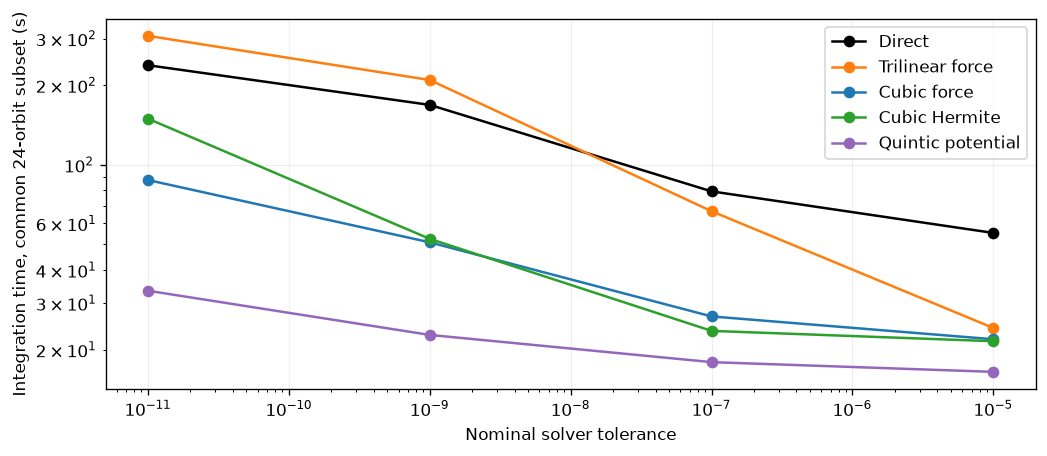

Evaluator          Tolerance  Successful  Full library (s)  Partial sum (s)
Direct             1e-11      24          237.80            237.80         
Direct             1e-09      24          168.38            168.38         
Direct             1e-07      24          79.35             79.35          
Direct             1e-05      24          55.27             55.27          
Trilinear force    1e-11      24          307.01            307.01         
Trilinear force    1e-09      24          209.13            209.13         
Trilinear force    1e-07      24          66.75             66.75          
Trilinear force    1e-05      24          24.17             24.17          
Cubic force        1e-11      24          87.58             87.58          
Cubic force        1e-09      24          50.93             50.93          
Cubic force        1e-07      24          26.73             26.73          
Cubic force        1e-05      24          21.91             21.91          
Cubic Hermit

In [3]:
construction = {}
for directory in RUN_DIRS:
    for method in METHODS[1:]:
        path = directory / f"grid-{method}.json"
        if path.exists():
            try:
                row = json.loads(path.read_text())
            except json.JSONDecodeError:
                print("Record being written or incomplete:", path.name)
                continue
            if method in construction and construction[method] != row:
                raise ValueError(f"Conflicting grid setup: {method}")
            construction[method] = row
table(["Evaluator", "Grid compile (s)", "Construct (s)", "Table MiB"],
      [[LABELS[m], f"{r['compilation_seconds']:.3f}",
        f"{r['construction_seconds']:.3f}", f"{r['bytes']/2**20:.3f}"]
       for m, r in construction.items()])

runtime_rows = []
# One common successful subset across all currently comparable groups.
comparable_tolerances = [t for t in TOLERANCES if all(
    any(i_method == m and i_tol == t and r["successful"]
        for (_, i_method, i_tol), r in records.items()) for m in METHODS)]
common_indices = set(range(N_ORBITS))
for t in comparable_tolerances:
    for m in METHODS:
        common_indices &= {i for (i, method, tol), r in records.items()
                           if method == m and tol == t and r["successful"]}
if not comparable_tolerances:
    common_indices = set()
print(f"Matched timing subset: {len(common_indices)}/{N_ORBITS} orbits")
print("Orbit IDs:", sorted(common_indices))
fig, ax = plt.subplots()
for method in METHODS:
    totals = []
    for tolerance in TOLERANCES:
        rows = [r for (_, m, t), r in records.items() if m == method and t == tolerance]
        ok = [r for r in rows if r["successful"]]
        complete = len(ok) == N_ORBITS
        elapsed = sum(r.get("integration_seconds", 0) for r in ok)
        runtime_rows.append([LABELS[method], f"{tolerance:.0e}", len(ok),
                             f"{elapsed:.2f}" if complete else "pending",
                             f"{elapsed:.2f}"])
        matched = [r for r in ok if r["index"] in common_indices]
        totals.append(sum(r["integration_seconds"] for r in matched)
                      if tolerance in comparable_tolerances and common_indices
                      else np.nan)
    ax.plot(TOLERANCES, totals, "o-", color=COLORS[method], label=LABELS[method])
ax.set(xscale="log", yscale="log", xlabel="Nominal solver tolerance",
       ylabel=f"Integration time, common {len(common_indices)}-orbit subset (s)")
ax.legend()
plt.show()
table(["Evaluator", "Tolerance", "Successful", "Full library (s)", "Partial sum (s)"],
      runtime_rows)

## Physical-energy drift and adaptive work

Energy drift is `(E(t) − E(0)) / ⟨|v|²⟩ref`. The denominator is the mean-square
speed over all 50,000 saved samples of the **same orbit's direct-force `1e-11`
reference trajectory**, shared across all evaluators and tolerances. It is not
relative to initial energy and does not depend on the potential's additive zero.
Nominal tolerance remains a normalized state tolerance, not an energy bound.

Stored errors use the integrator's launch scale; the notebook converts them to
the reference kinetic scale without changing the saved data or integrator.
Maximum errors include all saved samples and the exact endpoint. Energy points
with unavailable reference scales are omitted; adaptive-step points do not need
a reference. Partial groups are not representative full-library comparisons.
Position and velocity trajectory-error plots retain their original launch scales.

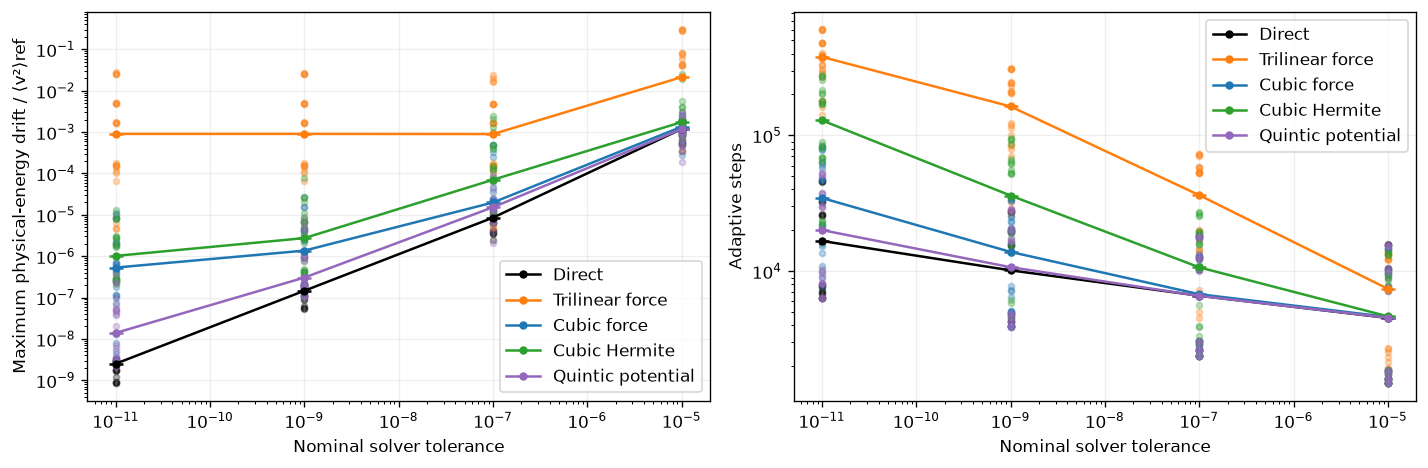

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for method in METHODS:
    median_tolerances, median_errors = [], []
    step_tolerances, median_steps = [], []
    for tolerance in TOLERANCES:
        rows = [r for (_, m, t), r in records.items()
                if m == method and t == tolerance and r["successful"]]
        if not rows:
            continue
        errors = [r["diagnostics"]["max_energy_error"] * energy_factors[r["index"]]
                  for r in rows if r["index"] in energy_factors]
        if errors:
            median_tolerances.append(tolerance)
            median_errors.append(np.median(errors))
        steps = [r["diagnostics"]["num_steps"] for r in rows]
        step_tolerances.append(tolerance)
        median_steps.append(np.median(steps))
        for ax, values in zip(axes, [errors, steps]):
            if not values:
                continue
            ax.scatter([tolerance]*len(values), values, s=13, alpha=.3,
                       color=COLORS[method])
            ax.scatter(tolerance, np.median(values), s=65, marker="_",
                       color=COLORS[method])
    axes[0].plot(median_tolerances, median_errors, "o-",
                 color=COLORS[method], label=LABELS[method], markersize=4)
    axes[1].plot(step_tolerances, median_steps, "o-",
                 color=COLORS[method], label=LABELS[method], markersize=4)
for ax, ylabel in zip(axes, ["Maximum physical-energy drift / ⟨v²⟩ref", "Adaptive steps"]):
    ax.set(xscale="log", yscale="log", xlabel="Nominal solver tolerance", ylabel=ylabel)
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

## Selected orbit: trajectories

Change `ORBIT_INDEX` and `SELECTED_TOLERANCE` above, then rerun. Comparisons use
the same launch, shell clock, random sampling key, and output times. The
`1e-11` direct trajectory is a numerical reference; its own convergence error
is not zero. Long-time trajectory separation for sensitive orbits is not by
itself an observable-error estimate or proof of chaos.

Orbit 16: StationaryGrid; clock=59.8893 Myr; tolerance=1e-09
Available: direct, linear, cubic, hermite, quintic


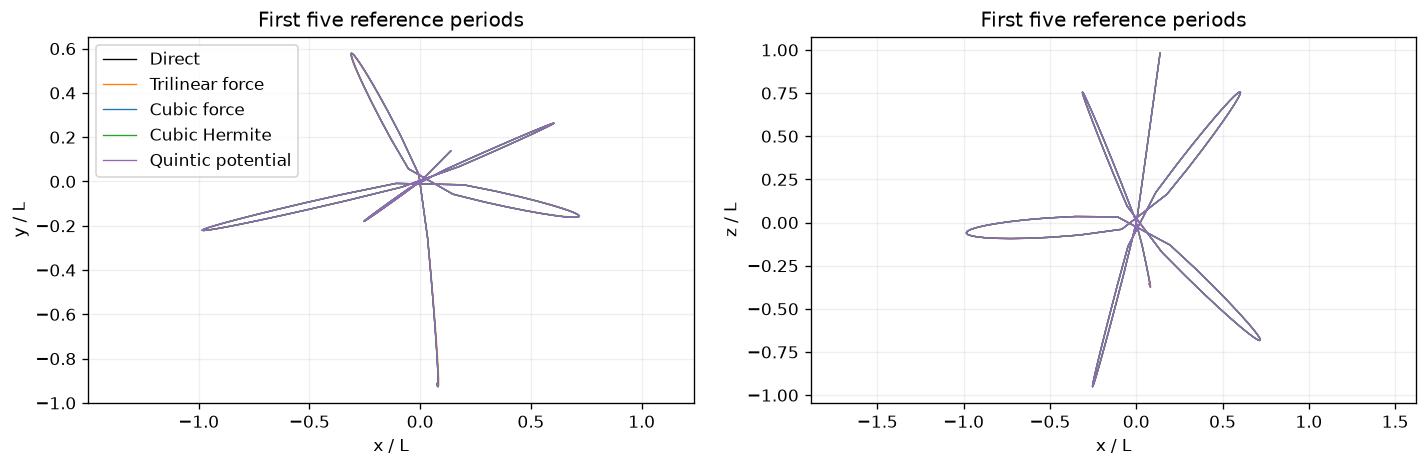

In [5]:
def read_trajectory(index, method, tolerance):
    row = records.get((index, method, tolerance))
    if not row or not row["successful"]:
        return None
    path = row["path"].with_suffix(".npz")
    if not path.exists():
        return None
    with np.load(path, allow_pickle=False) as saved:
        return {key: saved[key] for key in saved.files}

launch_file = next((d / "launches.npz" for d in RUN_DIRS
                    if (d / "launches.npz").exists()), None)
if launch_file is None:
    raise FileNotFoundError("No launch file yet; rerun after setup completes")
with np.load(launch_file, allow_pickle=False) as saved:
    launches = {key: saved[key] for key in saved.files}
assert 0 <= ORBIT_INDEX < len(launches["periods"])
period = launches["periods"][ORBIT_INDEX]
q0, v0 = launches["positions"][ORBIT_INDEX], launches["velocities"][ORBIT_INDEX]
length = max(np.linalg.norm(q0), np.linalg.norm(v0) * period/(2*np.pi))
speed = 2*np.pi*length/period
selected = {method: data for method in METHODS
            if (data := read_trajectory(ORBIT_INDEX, method, SELECTED_TOLERANCE)) is not None}
reference = read_trajectory(ORBIT_INDEX, "direct", REFERENCE_TOLERANCE)
print(f"Orbit {ORBIT_INDEX}: {launches['sampler'][ORBIT_INDEX]}; "
      f"clock={period:.6g} Myr; tolerance={SELECTED_TOLERANCE:.0e}")
print("Available:", ", ".join(selected) or "none yet")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for method, data in selected.items():
    subset = np.flatnonzero(data["times_Myr"] / period <= 5)[::PLOT_STRIDE]
    q = data["positions_kpc"][subset] / length
    for ax, y in zip(axes, [1, 2]):
        ax.plot(q[:, 0], q[:, y], lw=.8, color=COLORS[method], label=LABELS[method])
for ax, y in zip(axes, ["y", "z"]):
    ax.set(xlabel="x / L", ylabel=f"{y} / L", title="First five reference periods")
    ax.set_aspect("equal", adjustable="datalim")
if selected:
    axes[0].legend()
plt.tight_layout()
plt.show()

## Selected orbit: intrinsic (x, y, vz) density marginals

Use only the second half of each trajectory (last 25,000 saved samples),
without plotting subsampling. The reference bounds use that same second half. Histogram edges come from
this orbit's direct `1e-11` reference, padded by 30% of each coordinate span at
each end, and are shared by all evaluators. Each 3D count is divided by the
**second-half sample count and bin volume**. Thus each displayed marginal
integrates to the fraction inside the joint 3D bounds, not automatically one.
Samples outside any of the three bounds are reported in the table.

Rows compare the reference and the selected tolerance for each available force
evaluator; columns show `(x,y)`, `(x,vz)`, and `(y,vz)`. Each column shares one
logarithmic color scale across rows. Blank bins have zero counts; no smoothing,
PSF, spatial symmetry operation, or fitted orbit weight is applied. This is a
short-axis projection in intrinsic coordinates, not the configured observer view.

Orbit 16: shared (20, 20, 30) histogram, second half only
Coordinate  Lower bound  Upper bound
x (kpc)     -15.5519     15.7308    
y (kpc)     -15.348      15.1542    
vz (km/s)   -3438.82     3426.99    
Evaluator                  Outside joint (x,y,vz) bounds  Marginal integral
Direct reference (1e-11)   0.0000%                        1.000000         
Direct (1e-09)             0.0000%                        1.000000         
Trilinear force (1e-09)    0.0000%                        1.000000         
Cubic force (1e-09)        0.0000%                        1.000000         
Cubic Hermite (1e-09)      0.0000%                        1.000000         
Quintic potential (1e-09)  0.0000%                        1.000000         


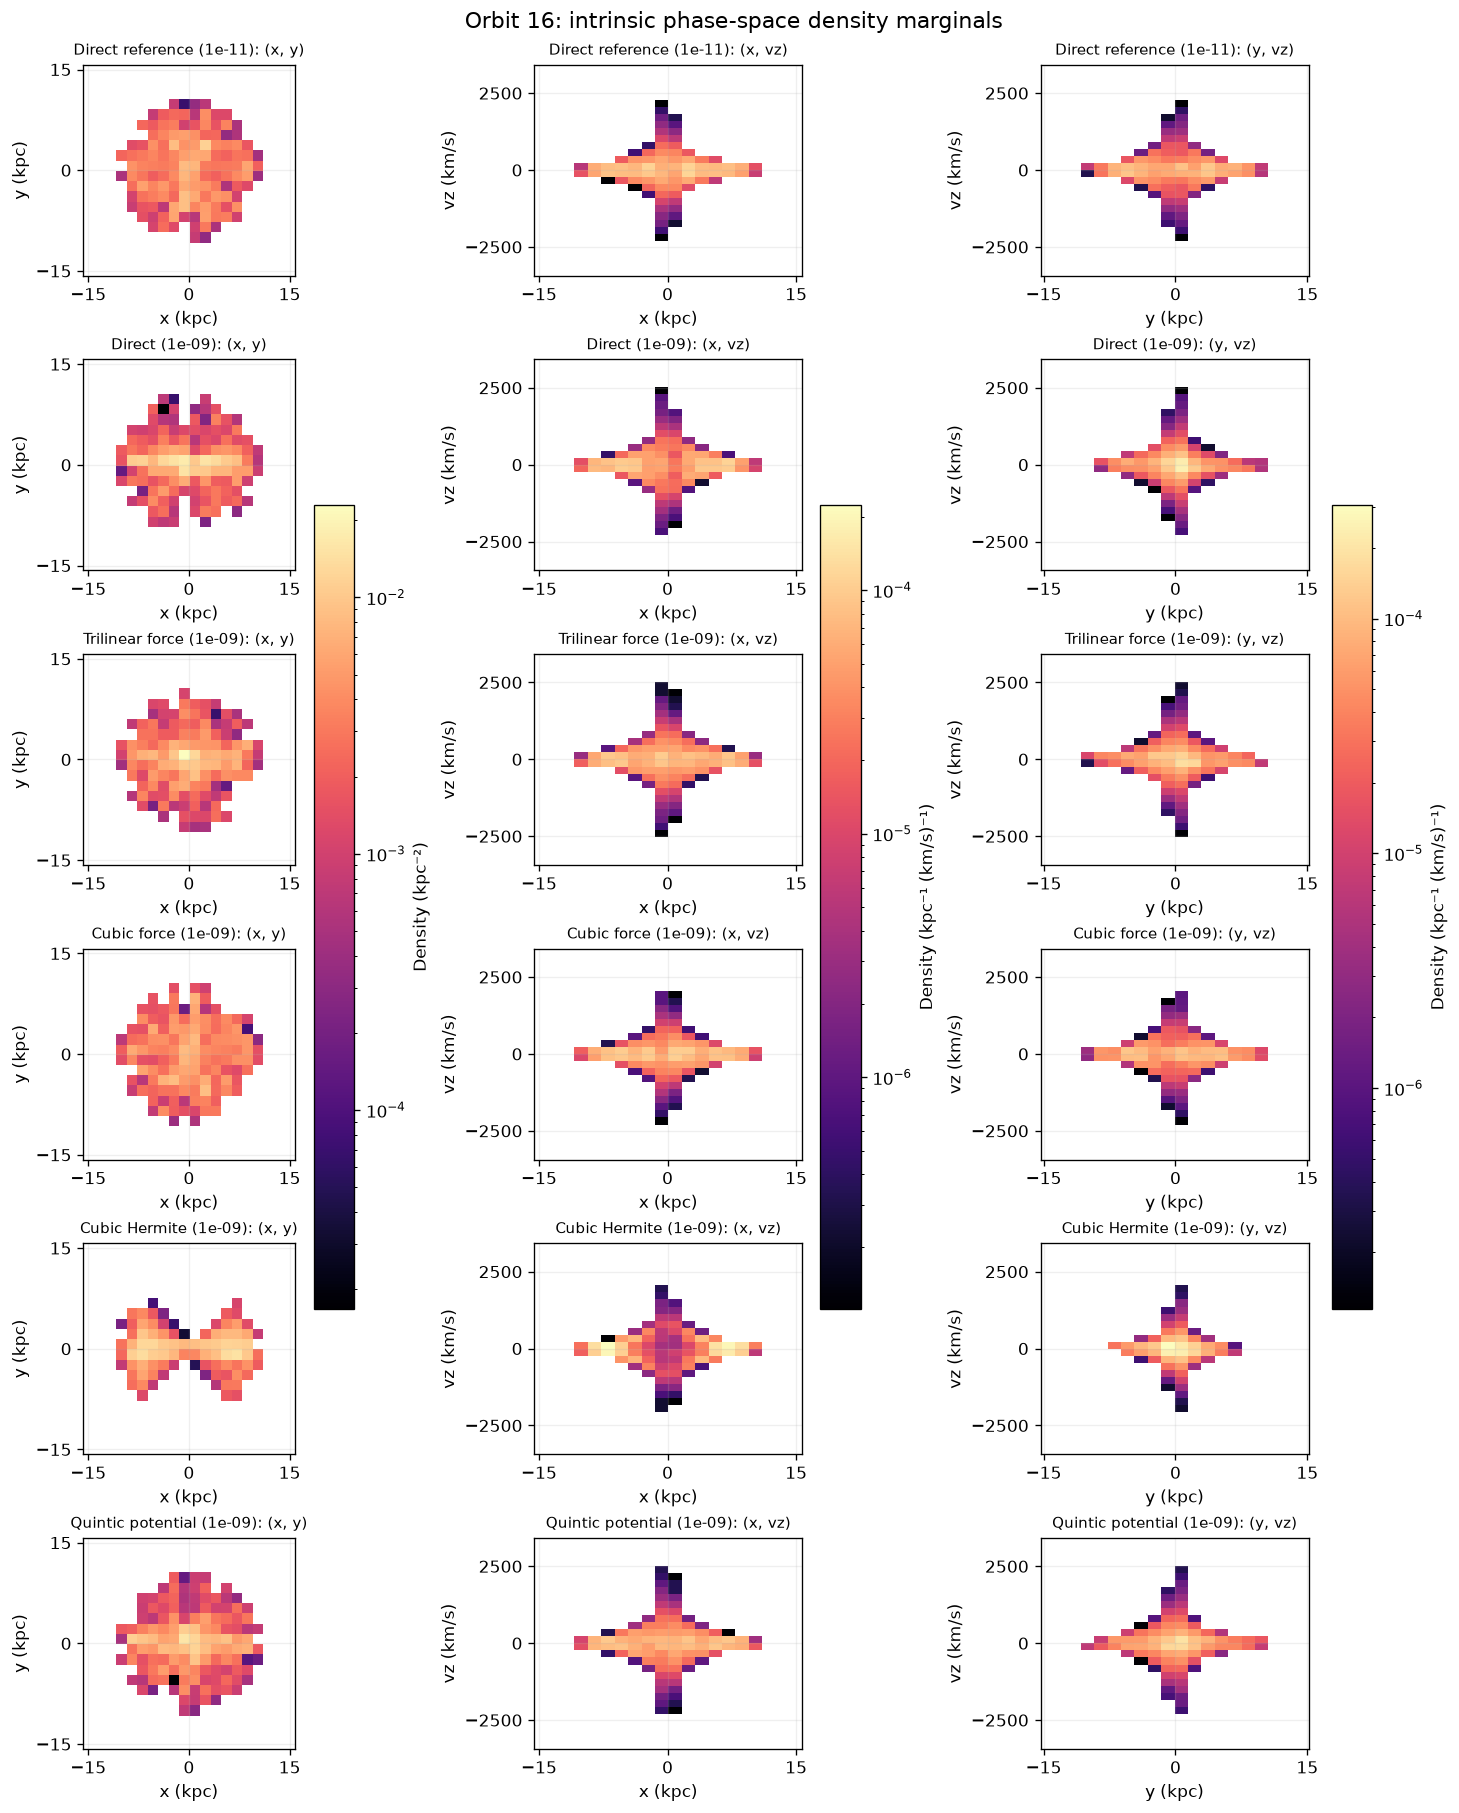

In [6]:
from matplotlib.colors import LogNorm
from matplotlib.ticker import MaxNLocator

DENSITY_BINS = (20, 20, 30)
DENSITY_PADDING = 0.30  # Add 30% of the reference span at EACH end.
KPC_PER_MYR_TO_KMS = 3.085677581491367e16 / (365.25 * 86400 * 1e6)


def phase_samples(data):
    start = len(data["times_Myr"]) // 2
    return np.column_stack([data["positions_kpc"][start:, :2],
                            data["velocities_kpc_Myr"][start:, 2] * KPC_PER_MYR_TO_KMS])


def orbit_density(samples, edges):
    # Never normalize to the number of samples that happen to fall inside.
    counts, _ = np.histogramdd(samples, bins=edges, density=False)
    widths = [np.diff(edge) for edge in edges]
    volume = widths[0][:, None, None] * widths[1][None, :, None] * widths[2][None, None, :]
    density = counts / (len(samples) * volume)
    marginals = [np.sum(density * widths[2][None, None, :], axis=2),
                 np.sum(density * widths[1][None, :, None], axis=1),
                 np.sum(density * widths[0][:, None, None], axis=0)]
    inside = counts.sum() / len(samples)
    areas = [widths[0][:, None] * widths[1][None, :],
             widths[0][:, None] * widths[2][None, :],
             widths[1][:, None] * widths[2][None, :]]
    for marginal, area in zip(marginals, areas):
        np.testing.assert_allclose(np.sum(marginal * area), inside, atol=1e-12)
    return marginals, 1 - inside


if reference is None:
    print("Direct 1e-11 reference pending; density plots omitted.")
else:
    reference_samples = phase_samples(reference)
    low, high = reference_samples.min(axis=0), reference_samples.max(axis=0)
    # Handle a degenerate coordinate without zero-width bins.
    span = np.maximum(high - low, np.maximum(np.maximum(abs(low), abs(high)), 1.) * 1e-12)
    edges = [np.linspace(lo - DENSITY_PADDING * width,
                         hi + DENSITY_PADDING * width, bins + 1)
             for lo, hi, width, bins in zip(low, high, span, DENSITY_BINS)]
    entries = [(f"Direct reference ({REFERENCE_TOLERANCE:.0e})", reference)]
    entries += [(f"{LABELS[method]} ({SELECTED_TOLERANCE:.0e})", data)
                for method, data in selected.items()]
    density_rows = [(label, *orbit_density(phase_samples(data), edges))
                    for label, data in entries]
    print(f"Orbit {ORBIT_INDEX}: shared {DENSITY_BINS} histogram, second half only")
    table(["Coordinate", "Lower bound", "Upper bound"],
          [[name, f"{edge[0]:.6g}", f"{edge[-1]:.6g}"]
           for name, edge in zip(["x (kpc)", "y (kpc)", "vz (km/s)"], edges)])
    table(["Evaluator", "Outside joint (x,y,vz) bounds", "Marginal integral"],
          [[label, f"{outside:.4%}", f"{1-outside:.6f}"]
           for label, _, outside in density_rows])

    fig, axes = plt.subplots(len(density_rows), 3,
                             figsize=(12, 2.5 * len(density_rows)),
                             squeeze=False, layout="constrained")
    pairs = [(0, 1), (0, 2), (1, 2)]
    axis_labels = ["x (kpc)", "y (kpc)", "vz (km/s)"]
    density_units = ["kpc⁻²", "kpc⁻¹ (km/s)⁻¹", "kpc⁻¹ (km/s)⁻¹"]
    for column, (a, b) in enumerate(pairs):
        positive = np.concatenate([marginals[column][marginals[column] > 0]
                                   for _, marginals, _ in density_rows])
        norm = LogNorm(vmin=positive.min(), vmax=max(positive.max(), positive.min()*1.01))
        for row, (label, marginals, _) in enumerate(density_rows):
            ax = axes[row, column]
            image = ax.pcolormesh(edges[a], edges[b],
                                 np.ma.masked_less_equal(marginals[column].T, 0),
                                 norm=norm, cmap="magma", shading="flat", rasterized=True)
            ax.set(xlabel=axis_labels[a], ylabel=axis_labels[b])
            ax.set_title(f"{label}: ({['x','y','vz'][a]}, {['x','y','vz'][b]})", fontsize=9)
            ax.xaxis.set_major_locator(MaxNLocator(3))
            ax.yaxis.set_major_locator(MaxNLocator(3))
            if column == 0:
                extent = max(abs(edges[0]).max(), abs(edges[1]).max())
                ax.set(xlim=(-extent, extent), ylim=(-extent, extent))
                ax.set_aspect("equal", adjustable="box")
        fig.colorbar(image, ax=axes[:, column].tolist(), label=f"Density ({density_units[column]})",
                     shrink=.7)
    fig.suptitle(f"Orbit {ORBIT_INDEX}: intrinsic phase-space density marginals", fontsize=13)
    plt.show()

## Reading the results

- Compare complete libraries or identical matched orbit subsets; do not rank
  partial totals against complete totals.
- Tightening tolerance isolates solver sensitivity, but does not remove force
  interpolation error. Compare direct tolerances as well as interpolators.
- Hermite can conserve its approximate Hamiltonian while differing from the
  physical one. Both histories matter; conservation alone is not force accuracy.
- Grid setup is paid per physical model. Current integration sums exclude it;
  compilation reuse and production-library throughput need separate treatment.
- Next: retained-distribution comparisons and trajectory-error summaries,
  and repeated/interleaved timing controls once the matrix is complete.

## Weighted median absolute 3D-density error for every orbit

For each orbit, use its direct-force `1e-11` trajectory's **second half** to
construct shared `(x,y,vz)` edges with 30% padding at each end. Use the same
`DENSITY_BINS` as the selected-orbit density panels above. Count each evaluator's
second-half samples on those edges, normalized by its total second-half sample
count and bin volume.

Within reference-occupied bins, calculate `100 × |ρ − ρref| / ρref`, then take
the median weighted by reference probability mass. Equal-volume bins make this
equivalent to normalized reference-density weighting. Reference-empty bins have
undefined relative errors; their probability mass, and out-of-bounds mass, are
retained separately in `orbit_density_errors` rather than folded into the median.

Each thin line is **one orbit's weighted median absolute error** across nominal
tolerances. The bold line is the unweighted median of those orbit-level values.
Panels share scales; symmetric-log y retains exact zeros. The direct `1e-11`
self-comparison is exactly zero by construction. These are histogram differences,
not uncertainty estimates; the median can hide errors affecting less than half
of the reference mass. Hermite's hard boundary switch need not preserve one
globally smooth Hamiltonian.

Density comparisons: 480/480


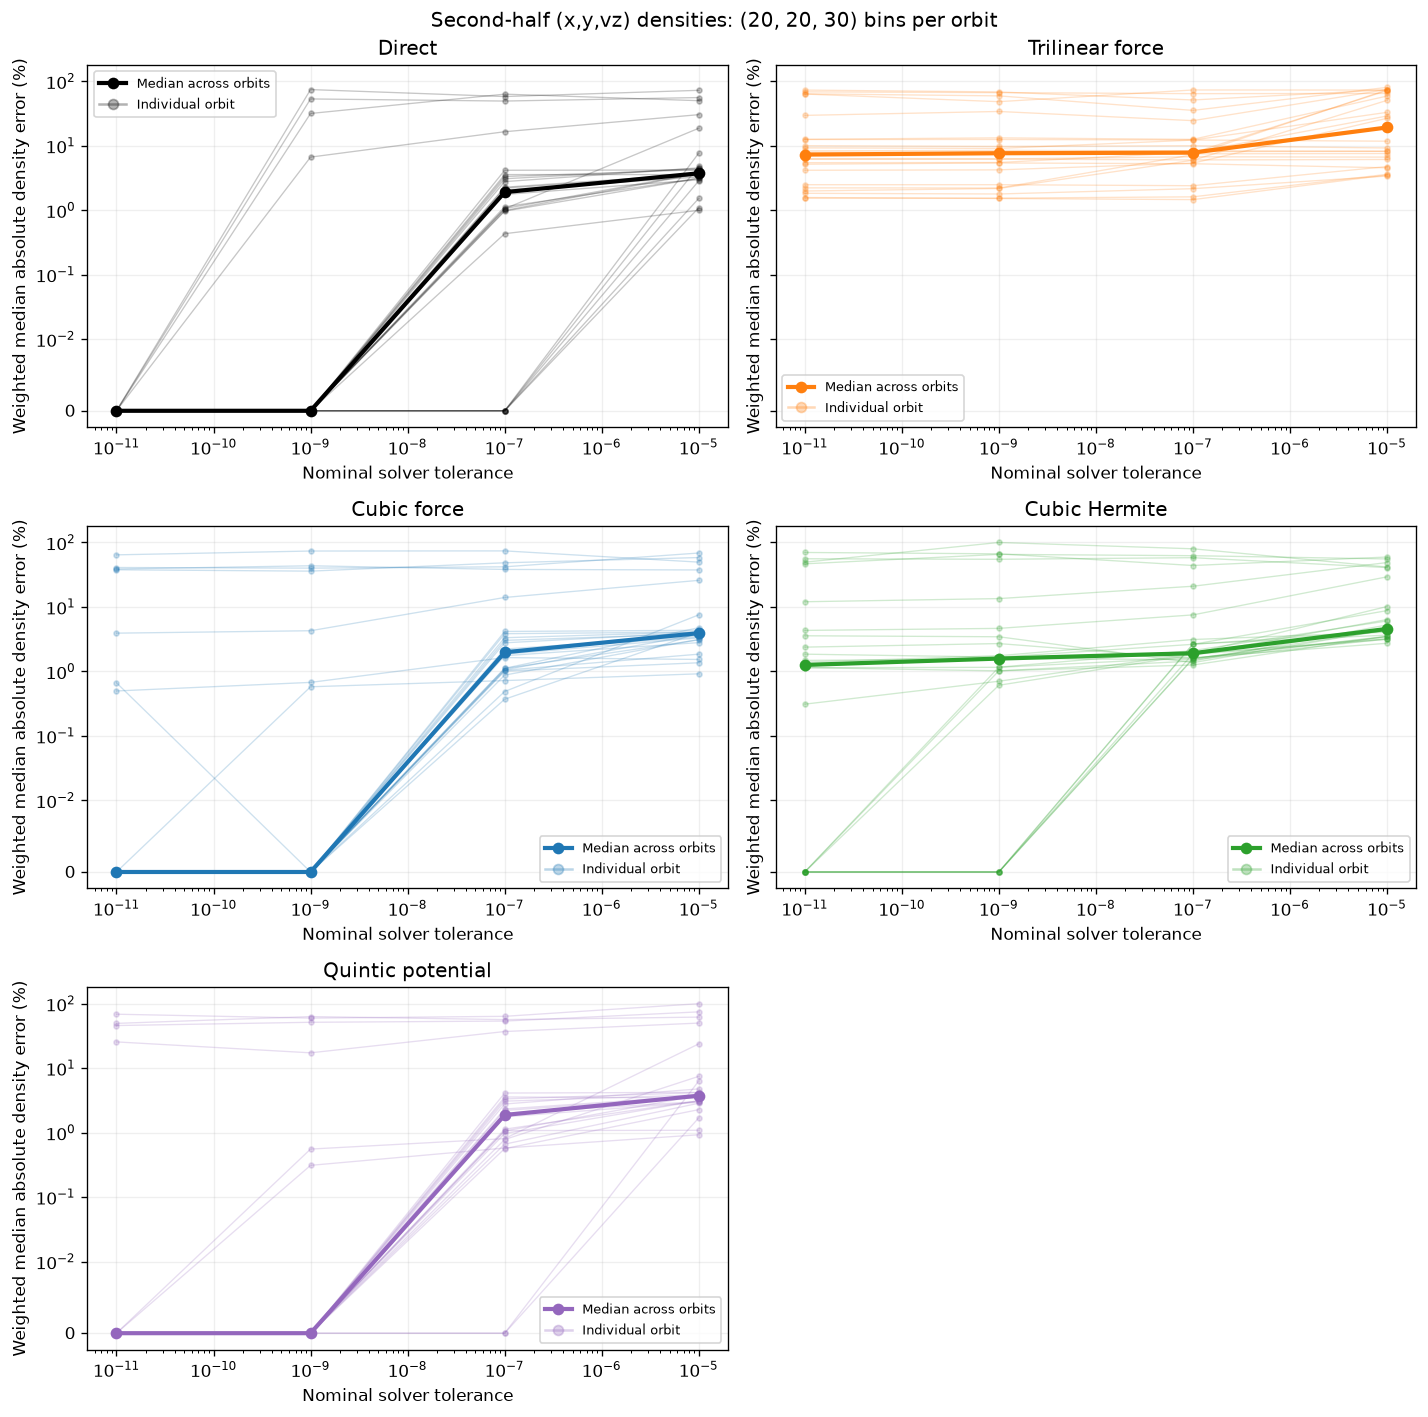

Evaluator          Tolerance  Orbits  Median orbit error (%)  Largest orbit error (%)
Direct             1e-11      24      0                       0                      
Direct             1e-09      24      0                       74.34                  
Direct             1e-07      24      1.908                   63.16                  
Direct             1e-05      24      3.739                   72.41                  
Trilinear force    1e-11      24      7.297                   73.02                  
Trilinear force    1e-09      24      7.651                   68.36                  
Trilinear force    1e-07      24      7.827                   73.33                  
Trilinear force    1e-05      24      19.22                   80.47                  
Cubic force        1e-11      24      0                       64.29                  
Cubic force        1e-09      24      0                       73.68                  
Cubic force        1e-07      24      1.979           

In [7]:
def weighted_median(values, weights):
    order = np.argsort(values)
    cumulative = np.cumsum(weights[order])
    index = np.searchsorted(cumulative, .5 * cumulative[-1], side="left")
    return float(values[order[min(index, len(order) - 1)]])


def reference_edges(samples):
    low, high = samples.min(axis=0), samples.max(axis=0)
    span = np.maximum(high - low, np.maximum(np.maximum(abs(low), abs(high)), 1.) * 1e-12)
    return [np.linspace(lo - DENSITY_PADDING * width,
                        hi + DENSITY_PADDING * width, bins + 1)
            for lo, hi, width, bins in zip(low, high, span, DENSITY_BINS)]


def density_error_summary(samples, edges, reference_probability):
    counts, _ = np.histogramdd(samples, bins=edges)
    probability = counts / len(samples)
    occupied = reference_probability > 0
    weights = reference_probability[occupied]
    errors = 100 * abs(probability[occupied] - weights) / weights
    return {
        "weighted_median_absolute_error_percent": weighted_median(errors, weights),
        "probability_in_reference_empty_bins": float(probability[~occupied].sum()),
        "probability_outside_bounds": float(max(0., 1 - probability.sum())),
        "reference_mass_at_exact_zero_error": float(weights[errors == 0].sum()),
    }


orbit_density_errors = []
missing_density_cases = []
for index in range(N_ORBITS):
    ref_data = read_trajectory(index, "direct", REFERENCE_TOLERANCE)
    if ref_data is None:
        missing_density_cases.append((index, "reference", REFERENCE_TOLERANCE))
        continue
    ref_samples = phase_samples(ref_data)
    orbit_edges = reference_edges(ref_samples)
    ref_counts, _ = np.histogramdd(ref_samples, bins=orbit_edges)
    ref_probability = ref_counts / len(ref_samples)
    np.testing.assert_allclose(ref_probability.sum(), 1., atol=1e-12)
    for method in METHODS:
        for tolerance in TOLERANCES:
            data = read_trajectory(index, method, tolerance)
            if data is None:
                missing_density_cases.append((index, method, tolerance))
                continue
            summary = density_error_summary(phase_samples(data), orbit_edges, ref_probability)
            orbit_density_errors.append({"index": index, "method": method,
                                         "tolerance": tolerance, **summary})
print(f"Density comparisons: {len(orbit_density_errors)}/{N_ORBITS*len(METHODS)*len(TOLERANCES)}")
if missing_density_cases:
    print("Unavailable cases:", missing_density_cases)

fig, axes = plt.subplots(3, 2, figsize=(12, 12), sharex=True, sharey=True)
for unused_ax in axes.flat[len(METHODS):]:
    unused_ax.set_visible(False)
for ax, method in zip(axes.flat, METHODS):
    for index in range(N_ORBITS):
        values = {r["tolerance"]: r["weighted_median_absolute_error_percent"]
                  for r in orbit_density_errors if r["method"] == method and r["index"] == index}
        ax.plot(TOLERANCES, [values.get(t, np.nan) for t in TOLERANCES],
                "o-", color=COLORS[method], alpha=.22, linewidth=.8, markersize=3)
    medians = []
    for tolerance in TOLERANCES:
        values = [r["weighted_median_absolute_error_percent"] for r in orbit_density_errors
                  if r["method"] == method and r["tolerance"] == tolerance]
        medians.append(np.median(values) if values else np.nan)
    ax.plot(TOLERANCES, medians, "o-", color=COLORS[method], linewidth=2.5,
            markersize=6, label="Median across orbits")
    ax.plot([], [], "o-", color=COLORS[method], alpha=.3, label="Individual orbit")
    ax.tick_params(axis="x", labelbottom=True)
    ax.set_xscale("log")
    ax.set_yscale("symlog", linthresh=.01)
    ax.set(title=LABELS[method], xlabel="Nominal solver tolerance",
           ylabel="Weighted median absolute density error (%)")
    ax.legend(fontsize=8)
fig.suptitle(f"Second-half (x,y,vz) densities: {DENSITY_BINS} bins per orbit")
plt.tight_layout()
plt.show()

rows = []
for method in METHODS:
    for tolerance in TOLERANCES:
        group = [r for r in orbit_density_errors if r["method"] == method and r["tolerance"] == tolerance]
        if group:
            values = [r["weighted_median_absolute_error_percent"] for r in group]
            rows.append([LABELS[method], f"{tolerance:.0e}", len(group),
                         f"{np.median(values):.4g}", f"{max(values):.4g}"])
table(["Evaluator", "Tolerance", "Orbits", "Median orbit error (%)", "Largest orbit error (%)"], rows)